# SANOS Direct-Observation EKF — evaluation & visualization

**"Option 2"**: filter the DLV² state by assimilating *raw market quotes* (a
price-space EKF), instead of fitting SANOS per snapshot and filtering the fit.
Each quote enters weighted by its own `R = (half-spread)²`, so a thin snapshot
contributes little rather than a toxic full-curve fit — no gating needed.

Structure: **1** data · **2** model training + persist baseline · **3** held-out
error over time · **4** snapshot inspection · **5** parameter sweep.

All metrics use the same full-market held-out NSE as `sanos_dlv_kf_eval_lean.ipynb`.
The model + metrics live in `sanos_ekf_eval.py`; this notebook only drives & plots.

In [8]:
import datetime as _dt
import os
import sys
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np

SANOS_DIR = "/Users/elie/Documents/GitHub/quant_data/personal/SANOS_KF_Strike"
os.chdir(SANOS_DIR)  # so phase1_cache.pkl resolves
if SANOS_DIR not in sys.path:
    sys.path.insert(0, SANOS_DIR)

import sanos_ekf_eval as E  # loads the phase1 cache on import

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
_ny = ZoneInfo("America/New_York")


def _ny_times(ts_posix):
    return np.array([_dt.datetime.fromtimestamp(s, tz=_ny) for s in ts_posix])


def _roll(a, w=200):
    "Rolling mean over the non-NaN entries, NaN-aligned back to the full axis."
    a = np.asarray(a, float)
    m = ~np.isnan(a)
    out = np.full_like(a, np.nan)
    if m.sum() == 0:
        return out
    idx = np.where(m)[0]
    out[idx] = np.convolve(a[idx], np.ones(w) / w, mode="same")
    return out

In [9]:
# ── Set the trade date — everything below reloads from phase1_cache_{TRADE_DATE}.pkl ──
TRADE_DATE = "2024-03-05"
E.load_cache(TRADE_DATE)
print(
    f"loaded phase1_cache_{E.TRADE_DATE}.pkl  ·  {len(E.results):,} snapshots  ·  N={E.N}  state={E.n_state}"
)

loaded phase1_cache_2024-03-05.pkl  ·  23,371 snapshots  ·  N=12  state=10


## 1 — Data

A single expiry, intraday, loaded from `phase1_cache.pkl`. `snap_lookup[ts]`
gives the full set of market `(strike, bid, ask)` per snapshot — the same data the
held-out NSE scores against.

In [10]:
fwds = np.array([r["fwd"] for r in E.results if not r["failed"] and r.get("fwd") is not None])
qps = [len(v[0]) for v in E.snap_lookup.values()]
t0 = _ny_times([E._tsec(E.results[0])])[0]
print(f"date              : {t0:%Y-%m-%d}")
print(f"snapshots         : {len(E.results):,}")
print(f"grid anchors (N)  : {E.N}   range {E.grid_K.min():.1f} .. {E.grid_K.max():.1f}")
print(f"DLV nodes (state) : {E.n_state}")
print(
    f"forward range     : {fwds.min():.2f} .. {fwds.max():.2f}  ({(fwds.max() - fwds.min()) / fwds.mean() * 100:.2f}%)"
)
print(f"time-to-expiry    : {E.tte:.5f} yr")
print(f"quotes / snapshot : median {int(np.median(qps))}  (min {min(qps)}, max {max(qps)})")

date              : 2024-03-05
snapshots         : 23,371
grid anchors (N)  : 12   range 482.6 .. 542.9
DLV nodes (state) : 10
forward range     : 504.92 .. 510.69  (1.14%)
time-to-expiry    : 0.00082 yr
quotes / snapshot : median 6  (min 1, max 10)


## 2 — Model training (EKF) + persist baseline

The EKF runs in one numpy pass over all snapshots. Defaults are the tuned optimum:
flat init (warm-start hurts — it seeds capped wing values), correlated process
noise (`ell≈2`), and `q_scale≈0.3` in DLV²²/trading-day (orders of magnitude
smaller than the fit-then-filter pipeline, whose observation *was* DLV²).

In [11]:
CFG = dict(q_scale=0.3, ell=2.0, p0_scale=1e-2, warm=False, correlated=True)

ekf = E.run(**CFG, return_arrays=True)
per = E.persist_baseline(return_arrays=True)

print("                    held-out          in-sample")
print("                  mean   median       mean")
print(f"EKF             {ekf['ho_mean']:6.3f} {ekf['ho_med']:7.3f}     {ekf['is_mean']:6.3f}")
print(f"persist-all     {per['ho_mean']:6.3f} {per['ho_med']:7.3f}")
print("gate (ref, fit-then-filter): mean 0.67  median 0.57")

                    held-out          in-sample
                  mean   median       mean
EKF              0.624   0.429      0.401
persist-all      3.636   0.561
gate (ref, fit-then-filter): mean 0.67  median 0.57


## 3 — Held-out error over time: persist vs EKF

Rolling mean of the one-step-ahead NSE (left), and the per-step NSE distribution
(right). The EKF's win is mostly in the **tail**: persist-all occasionally prices a
snapshot with a toxic previous fit and blows up; the EKF never does, so its mean
collapses toward its median.

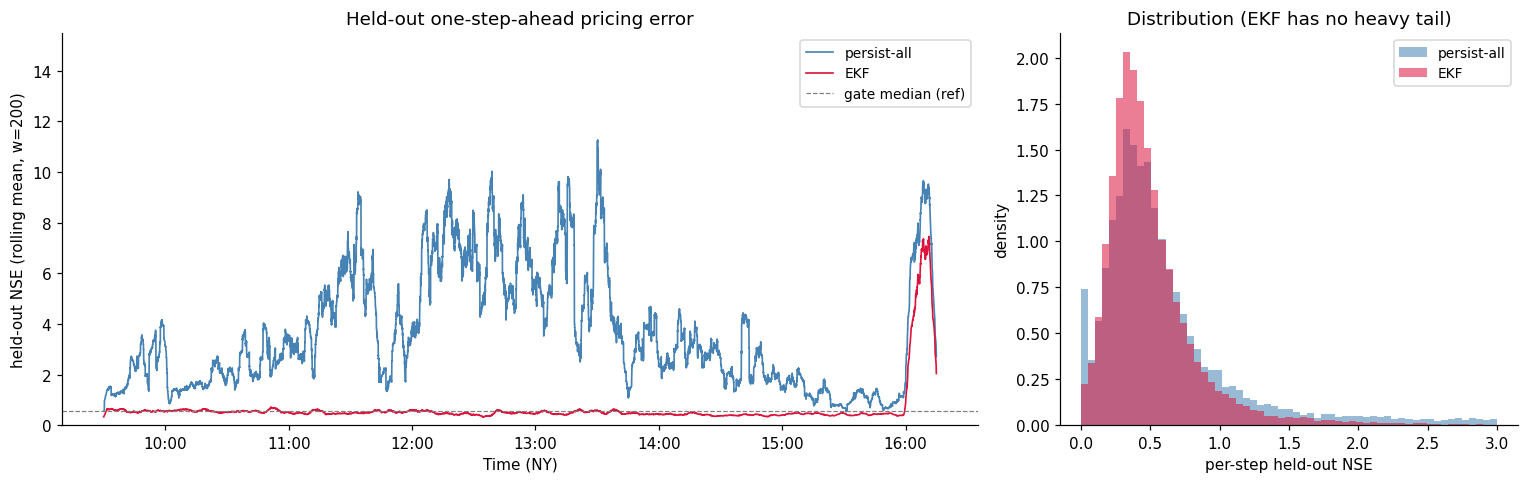

In [12]:
t = _ny_times(ekf["ts"])
fmt = plt.matplotlib.dates.DateFormatter("%H:%M", tz=_ny)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})

ax = axes[0]
ax.plot(t, _roll(per["nse_ho_arr"]), lw=1.1, color="steelblue", label="persist-all")
ax.plot(t, _roll(ekf["nse_ho_arr"]), lw=1.1, color="crimson", label="EKF")
ax.axhline(0.57, ls="--", lw=0.8, color="gray", label="gate median (ref)")
ax.set_ylabel("held-out NSE (rolling mean, w=200)")
ax.set_xlabel("Time (NY)")
ax.set_ylim(0, np.nanpercentile(per["nse_ho_arr"], 95))
ax.xaxis.set_major_formatter(fmt)
ax.set_title("Held-out one-step-ahead pricing error")
ax.legend(fontsize=9)

ax = axes[1]
bins = np.linspace(0, 3, 60)
ax.hist(
    per["nse_ho_arr"][~np.isnan(per["nse_ho_arr"])],
    bins=bins,
    density=True,
    alpha=0.55,
    color="steelblue",
    label="persist-all",
)
ax.hist(
    ekf["nse_ho_arr"][~np.isnan(ekf["nse_ho_arr"])],
    bins=bins,
    density=True,
    alpha=0.55,
    color="crimson",
    label="EKF",
)
ax.set_xlabel("per-step held-out NSE")
ax.set_ylabel("density")
ax.set_title("Distribution (EKF has no heavy tail)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 4 — Snapshot inspection: model vs market prices

Pick a well-populated mid-session snapshot and compare the EKF held-out density
(state propagated from the previous step) and the persist density (previous
snapshot's SANOS fit) against the live bid/ask. Right panel shows residuals in
half-spread units (±1 = the bid/ask edge).

snapshot threshold >= 10 quotes  ·  4265 candidates


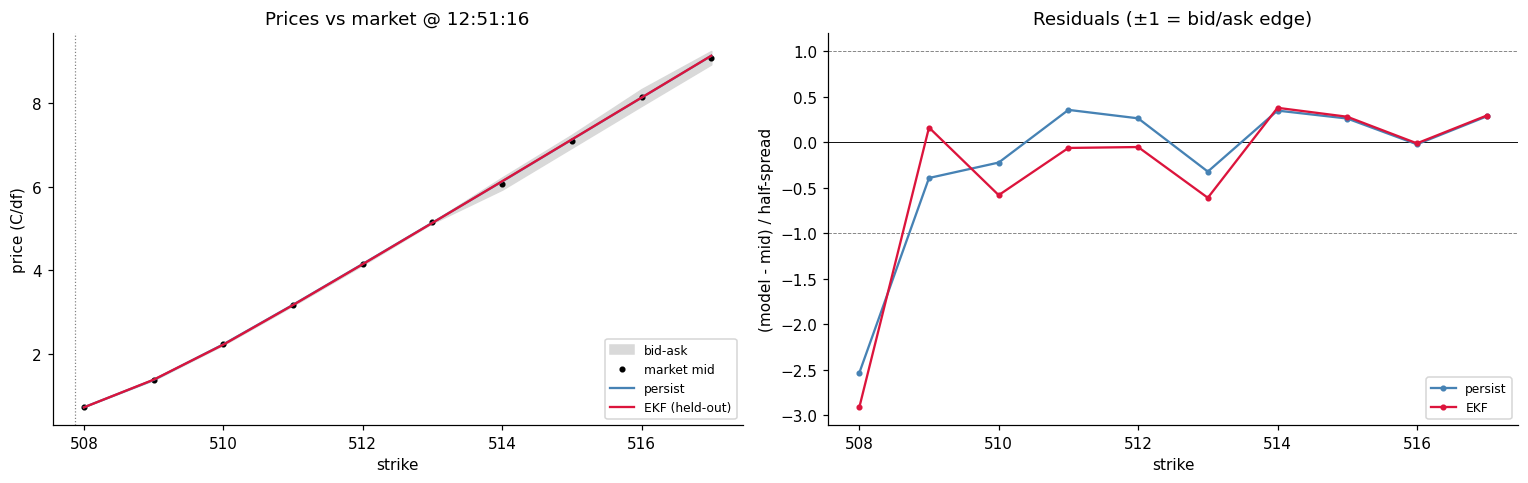

snapshot k=11865  held-out NSE: EKF 0.534   persist 0.500


In [13]:
# pick a well-populated mid-session snapshot — threshold adaptive to the date's quote density
_qps = np.array(
    [
        len(E.snap_lookup[r["ts"]][0])
        for r in E.results
        if not r["failed"] and r["ts"] in E.snap_lookup
    ]
)
thr = max(4, int(np.quantile(_qps, 0.90)))  # top-decile populated, but >=4 quotes
cand = [
    k
    for k, r in enumerate(E.results)
    if not r["failed"] and r["ts"] in E.snap_lookup and len(E.snap_lookup[r["ts"]][0]) >= thr
]
print(f"snapshot threshold >= {thr} quotes  ·  {len(cand)} candidates")
k = cand[len(cand) // 2]
r = E.results[k]
sk, bk, ak = E.snap_lookup[r["ts"]]
fwd = r["fwd"]
mid = 0.5 * (bk + ak)
hs = np.maximum(0.5 * (ak - bk), 1e-8)
isc = np.full(len(sk), E.is_call_flag)

d_ekf = E._density_eval(ekf["x_prior"][k], fwd)
px_ekf = E.option_prices(d_ekf, E.grid_K, sk, isc, fwd)

kprev = max(
    (j for j in range(k) if not E.results[j]["failed"] and E.results[j].get("dlvsqs") is not None),
    default=None,
)
d_per = E._density_eval(E.results[kprev]["dlvsqs"][0], fwd) if kprev is not None else None
px_per = E.option_prices(d_per, E.grid_K, sk, isc, fwd) if d_per is not None else None

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
ax.fill_between(sk, bk, ak, color="0.85", label="bid-ask")
ax.plot(sk, mid, "o", ms=3, color="black", label="market mid")
if px_per is not None:
    ax.plot(sk, px_per, "-", color="steelblue", label="persist")
ax.plot(sk, px_ekf, "-", color="crimson", label="EKF (held-out)")
ax.axvline(fwd, ls=":", color="gray", lw=0.8)
ax.set_xlabel("strike")
ax.set_ylabel("price (C/df)")
ax.set_title("Prices vs market @ %s" % _ny_times([ekf["ts"][k]])[0].strftime("%H:%M:%S"))
ax.legend(fontsize=8)

ax = axes[1]
for y in (-1, 0, 1):
    ax.axhline(y, ls="--" if y else "-", lw=0.6, color="gray" if y else "k")
if px_per is not None:
    ax.plot(sk, (px_per - mid) / hs, "o-", ms=3, color="steelblue", label="persist")
ax.plot(sk, (px_ekf - mid) / hs, "o-", ms=3, color="crimson", label="EKF")
ax.set_xlabel("strike")
ax.set_ylabel("(model - mid) / half-spread")
ax.set_title("Residuals (±1 = bid/ask edge)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

nse_e = np.mean(np.abs(px_ekf - mid) / hs)
nse_p = np.mean(np.abs(px_per - mid) / hs) if px_per is not None else np.nan
print(f"snapshot k={k}  held-out NSE: EKF {nse_e:.3f}   persist {nse_p:.3f}")

## 5 — Parameter sweep (q_scale × ell)

Held-out NSE across the responsiveness knob `q_scale` and the correlation length
`ell`, vs the gate reference. The optimum is a shallow basin around `q≈0.3-1`,
`ell≈2-5`; too-large `q` brings the tail back (mean diverges while median stays
low).

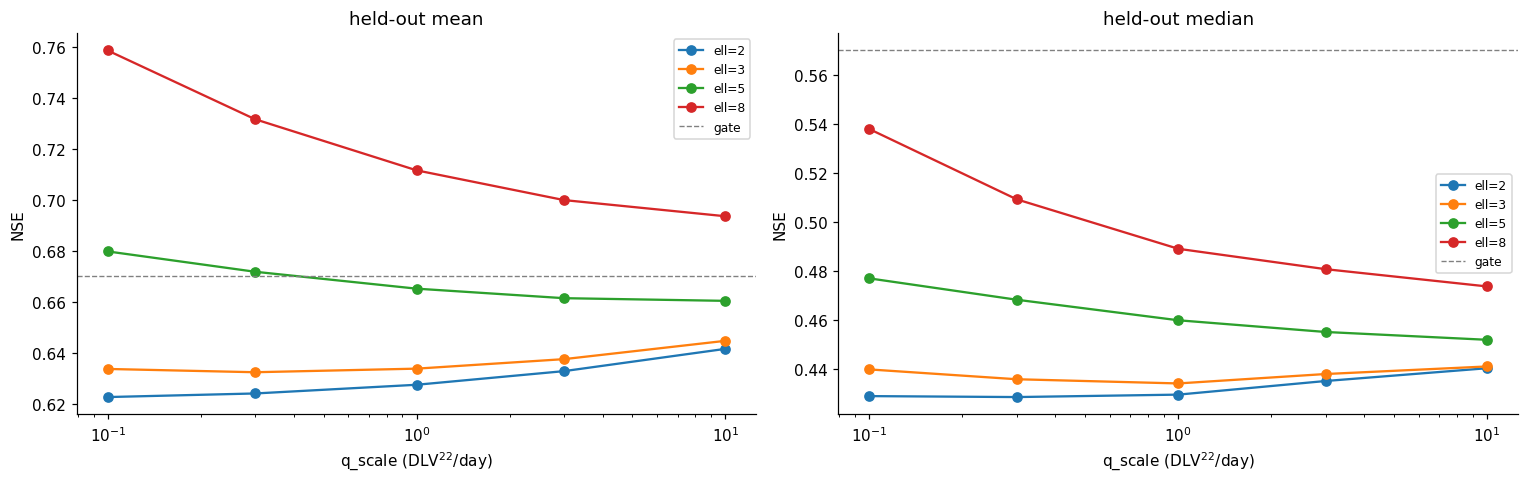

best held-out mean 0.623 at ell=2, q=0.1


In [14]:
qs = [0.1, 0.3, 1.0, 3.0, 10.0]
ells = [2.0, 3.0, 5.0, 8.0]
ho_mean = np.full((len(ells), len(qs)), np.nan)
ho_med = np.full((len(ells), len(qs)), np.nan)
for i, ell in enumerate(ells):
    for j, q in enumerate(qs):
        o = E.run(q_scale=q, ell=ell, p0_scale=1e-2, warm=False, correlated=True)
        ho_mean[i, j], ho_med[i, j] = o["ho_mean"], o["ho_med"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, M, name, ref in zip(
    axes, [ho_mean, ho_med], ["held-out mean", "held-out median"], [0.67, 0.57]
):
    for i, ell in enumerate(ells):
        ax.plot(qs, M[i], "o-", label=f"ell={ell:g}")
    ax.axhline(ref, ls="--", color="gray", lw=0.9, label="gate")
    ax.set_xscale("log")
    ax.set_xlabel("q_scale (DLV$^2$$^2$/day)")
    ax.set_ylabel("NSE")
    ax.set_title(name)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

bi = np.unravel_index(np.nanargmin(ho_mean), ho_mean.shape)
print(f"best held-out mean {ho_mean[bi]:.3f} at ell={ells[bi[0]]:g}, q={qs[bi[1]]:g}")

### Summary

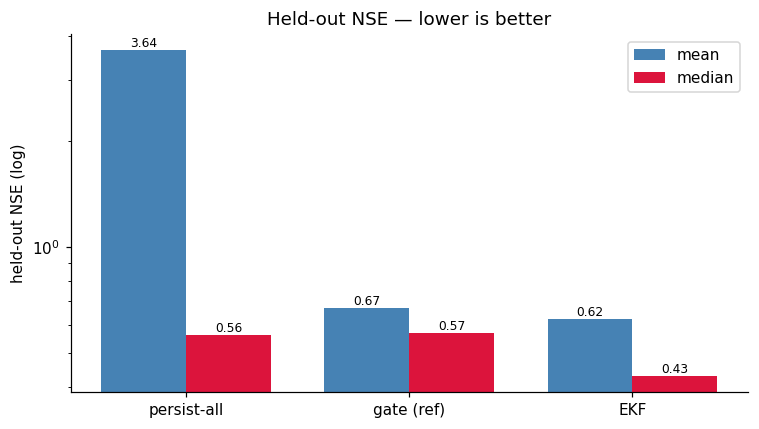

In [15]:
labels = ["persist-all", "gate (ref)", "EKF"]
means = [per["ho_mean"], 0.67, ekf["ho_mean"]]
meds = [per["ho_med"], 0.57, ekf["ho_med"]]
x = np.arange(3)
w = 0.38
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w / 2, means, w, label="mean", color="steelblue")
b2 = ax.bar(x + w / 2, meds, w, label="median", color="crimson")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("held-out NSE (log)")
ax.set_title("Held-out NSE — lower is better")
ax.bar_label(b1, fmt="%.2f", fontsize=8)
ax.bar_label(b2, fmt="%.2f", fontsize=8)
ax.legend()
plt.tight_layout()
plt.show()

the gatre ref is only for a specific date.